**Looped transformers series:** [01 Universal Transformer](01_universal_transformer.ipynb) · [02 Adaptive Computation Time](02_act_halting.ipynb) · [03 Recurrent depth](03_recurrent_depth.ipynb) · [04 Fixed point (DEQ)](04_deq_fixed_point.ipynb) · [05 Mixture-of-Recursions](05_mixture_of_recursions.ipynb) · **06 Relaxed recursion** · [07 Scratchpad memory](07_scratchpad_memory.ipynb) · [08 Layer-sharing schedules](08_layer_sharing.ipynb)

# Looped transformers 06 - Relaxed recursion: one shared block plus a tiny per-pass LoRA

A looped (recursive) transformer re-uses the same block several times, so it has the depth of a big model with the
parameters of a small one. The price is rigidity: with **strict weight tying every pass applies exactly the same function**.
*Relaxed Recursive Transformers* (Bae et al., 2024) loosen the tie with a tiny, per-pass low-rank correction
$W_t = W + B_t A_t$ (a LoRA per pass). Because $B_t$ starts at zero, the relaxed model starts *exactly* as the tied
model and training decides how much each pass should deviate. The paper also shows how to **turn an already-trained
stacked model into a recursive one**: initialise the shared block from the stacked layers (by averaging them, or by
keeping every other layer) and initialise each pass's LoRA from the **truncated SVD of the difference** between the
original layer and the shared block. In this notebook we build all of it from scratch in pure PyTorch, train a 4-layer
character model on Python docstrings, convert it, and measure what each choice buys.

| You will learn | Where |
|---|---|
| Why strict tying is restrictive and how a per-pass low-rank delta relaxes it | 1, 2 |
| How to write a LoRA linear layer that takes a *pass index* | 3 |
| Parameter accounting: $T \cdot r \cdot (d_{in} + d_{out})$ extra weights | 2, 4 |
| Why $B_t = 0$ makes the relaxed model start identical to the tied one (and why $\partial L/\partial A_t = 0$ at step 0) | 3 |
| How to convert a stacked model into a looped one (average / stepwise / random) | 8.1 |
| SVD initialisation of the per-pass LoRA vs zero initialisation | 8.2 |
| Rank sweep: parameters vs validation bits per character | 8.3 |
| What the learned deltas look like | 7 |

**Prerequisites:** Python, basic PyTorch (tensors, `nn.Module`, autograd, an optimizer loop), a rough idea of attention.
Notebook 01 of the series writes attention by hand; here we use `F.scaled_dot_product_attention`.

**Estimated runtime:** about 5-10 minutes on 2 CPU threads (depends on machine load) (the exact time is printed at the end).

## 1. Intuition

Think of a looped transformer as **one craftsman doing four passes over a piece of wood with the same tool**.
A stacked transformer has four craftsmen, each with their own tool: rough sawing, planing, sanding, polishing.
The single craftsman is cheaper (one salary) but every pass is identical, so the first pass cannot specialise in
"rough" and the last in "fine". Relaxed recursion gives the single craftsman **a tiny clip-on attachment per pass**:
the tool is the same, but pass 1 adds a coarse-grit attachment and pass 4 a fine one. Attachments are cheap (low
rank), and if we already *had* four specialists we can design each attachment so that "shared tool + attachment"
reproduces that specialist as closely as possible (the SVD initialisation).

Below: a 4-layer stacked model (left) and the relaxed recursive model we convert it into (right): two shared blocks
looped twice (the "cycle" pattern $A, B, A, B$), with one LoRA per (block, pass).

```mermaid
flowchart LR
    subgraph Stacked["Stacked: 4 distinct layers"]
        direction TB
        s_in[tokens + positions] --> L0[layer 0: W0] --> L1[layer 1: W1] --> L2[layer 2: W2] --> L3[layer 3: W3] --> s_out[LayerNorm + head]
    end
    subgraph Relaxed["Relaxed recursive: 2 shared blocks x 2 loops"]
        direction TB
        r_in[tokens + positions] --> P0["pass 0: block A<br/>W_A + B_A0 A_A0"] --> P1["pass 0: block B<br/>W_B + B_B0 A_B0"] --> P2["pass 1: block A<br/>W_A + B_A1 A_A1"] --> P3["pass 1: block B<br/>W_B + B_B1 A_B1"] --> r_out[LayerNorm + head]
    end
    L0 -. "avg(W0, W2) -> W_A<br/>SVD(W0 - W_A) -> B_A0 A_A0" .-> P0
    L2 -. "SVD(W2 - W_A) -> B_A1 A_A1" .-> P2
```

## 2. The math

**Shapes.** A batch of $B$ sequences of length $L$; each token is a vector of width $d$. Hidden state $X \in \mathbb{R}^{B\times L\times d}$.

**Stacked model** with $N$ layers: $X^{(\ell+1)} = f(X^{(\ell)};\,\theta_\ell)$ for $\ell = 0..N-1$, every layer has its own parameters $\theta_\ell$.

**Strictly tied looped model** with $K$ shared blocks looped $T$ times ($N = K\,T$ applications):
$$X^{(p+1)} = f\big(X^{(p)};\,\theta_{p \bmod K}\big), \qquad p = 0, \dots, KT-1 .$$
Position $p$ uses block $k = p \bmod K$ during loop (pass) $t = \lfloor p / K \rfloor$.

**Relaxed (per-pass LoRA).** Every linear map $y = W x + b$ inside block $k$ (with $W \in \mathbb{R}^{d_{out}\times d_{in}}$) becomes, during pass $t$,
$$y = \big(W + B_t A_t\big)\,x + b, \qquad A_t \in \mathbb{R}^{r\times d_{in}},\; B_t \in \mathbb{R}^{d_{out}\times r},\; r \ll \min(d_{in}, d_{out}).$$
$\Delta_t = B_t A_t$ is a rank-$\le r$ matrix. We never form it in the forward pass; we compute $B_t (A_t x)$, which costs $r(d_{in}+d_{out})$ multiply-adds per token instead of $d_{in} d_{out}$.
The LoRA paper multiplies $\Delta_t$ by $\alpha / r$; we use scale 1 (the scale can always be folded into $B_t$, and with SVD init it would only get in the way).

**Zero init.** $A_t \sim \mathcal{N}(0, 1/d_{in})$, $B_t = 0 \Rightarrow \Delta_t = 0$: the relaxed model *is* the tied model at step 0.
Gradients: $\frac{\partial \mathcal{L}}{\partial B_t} = G\,(A_t x)^\top \neq 0$ but $\frac{\partial \mathcal{L}}{\partial A_t} = B_t^\top G\, x^\top = 0$ where $G = \partial \mathcal{L}/\partial y$. So at the first step only $B$ moves.

**Extra parameters.** One relaxed linear layer used for $T$ passes adds
$$T \cdot r \cdot (d_{in} + d_{out})$$
parameters. Our block has $q,k,v,o$ ($d\to d$) and an MLP $d\to 4d \to d$, so per block and pass it adds $r\,(4\cdot 2d + 2\cdot 5d) = 18\,r\,d$.

**Converting a stacked model** ($N = 4$ layers $W_0..W_3$, $K = 2$ blocks, $T = 2$ loops; position $p = tK + k$ originally was layer $p$):
- *average:* $W_k^{\text{shared}} = \frac{1}{T}\sum_{t} W_{tK+k}$ (block A = mean of layers 0, 2; block B = mean of layers 1, 3),
- *stepwise:* keep every other layer, $W_k^{\text{shared}} = W_{2k}$ (block A = layer 0, block B = layer 2; layers 1 and 3 are dropped),
- *random:* fresh initialisation (embeddings and head are still copied from the stacked model in all three cases).

**SVD init of the per-pass LoRA.** The residual we would like pass $t$ of block $k$ to add is $R_{t,k} = W_{tK+k} - W_k^{\text{shared}}$. With SVD $R = U \Sigma V^\top$, the best rank-$r$ approximation (Eckart-Young) is $U_r \Sigma_r V_r^\top$, so we set
$$B_t = U_r \Sigma_r^{1/2}, \qquad A_t = \Sigma_r^{1/2} V_r^\top .$$
At $r = \min(d_{in}, d_{out})$ the stacked weight matrices are recovered exactly (biases and LayerNorms stay shared, so the *model* is still not exactly the stacked one).

## 3. Building blocks from scratch

### 3.0 Setup
Only the standard library, `torch`, `numpy` and `matplotlib`. Two CPU threads, fixed seeds.

In [1]:
import math
import time
import random
import importlib
import inspect
import re

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_num_threads(2)
NOTEBOOK_START = time.time()


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(0)
print("torch", torch.__version__, "| threads:", torch.get_num_threads())

torch 2.13.0 | threads: 2


### 3.1 A LoRA linear layer with a pass index

`RelaxedLinear` holds **one shared weight** `W` (shape `(d_out, d_in)`) and bias, plus **one pair $(A_t, B_t)$ per pass**, stored
as stacked tensors `lora_A: (T, r, d_in)` and `lora_B: (T, d_out, r)`. The forward pass takes the pass index `t`
and adds `B_t (A_t x)`. With `rank=0` it is an ordinary linear layer, which is how we get the stacked and the strictly tied models from the same code.

In [2]:
class RelaxedLinear(nn.Module):
    # y = (W + B_t A_t) x + b, where t is the pass index given to forward().

    def __init__(self, d_in: int, d_out: int, n_passes: int, rank: int) -> None:
        super().__init__()
        self.d_in, self.d_out, self.n_passes, self.rank = d_in, d_out, n_passes, rank
        self.weight = nn.Parameter(torch.randn(d_out, d_in) * 0.02)
        self.bias = nn.Parameter(torch.zeros(d_out))
        if rank > 0:
            # A random, B zero  ->  delta_t = B_t A_t = 0 at initialisation
            self.lora_A = nn.Parameter(torch.randn(n_passes, rank, d_in) / math.sqrt(d_in))
            self.lora_B = nn.Parameter(torch.zeros(n_passes, d_out, rank))

    def forward(self, x: torch.Tensor, t: int) -> torch.Tensor:
        y = F.linear(x, self.weight, self.bias)
        if self.rank > 0:
            low = x @ self.lora_A[t].T          # (..., r): project down to rank r
            y = y + low @ self.lora_B[t].T      # (..., d_out): project back up
        return y

    def delta(self, t: int) -> torch.Tensor:
        # the full (d_out, d_in) correction of pass t; only used for analysis
        if self.rank == 0:
            return torch.zeros(self.d_out, self.d_in)
        return self.lora_B[t] @ self.lora_A[t]

    def merged_weight(self, t: int) -> torch.Tensor:
        return self.weight + self.delta(t)

    def n_lora_params(self) -> int:
        return self.n_passes * self.rank * (self.d_in + self.d_out) if self.rank > 0 else 0

In [3]:
lin = RelaxedLinear(d_in=8, d_out=12, n_passes=3, rank=2)
x = torch.randn(2, 5, 8)                       # (B, L, d_in)
print("output shape:", tuple(lin(x, t=1).shape))
print("lora_A", tuple(lin.lora_A.shape), "| lora_B", tuple(lin.lora_B.shape))

# 1) at init B=0, so every pass gives exactly the plain linear output
for t in range(3):
    assert torch.equal(lin(x, t), F.linear(x, lin.weight, lin.bias))

# 2) the same equation two ways: low-rank path B(Ax) vs merged weight (W + BA) x
with torch.no_grad():
    lin.lora_B.normal_()
for t in range(3):
    assert torch.allclose(lin(x, t), F.linear(x, lin.merged_weight(t), lin.bias), atol=1e-5)

# 3) parameter accounting T * r * (d_in + d_out)
assert lin.n_lora_params() == 3 * 2 * (8 + 12) == lin.lora_A.numel() + lin.lora_B.numel()
print("extra LoRA params:", lin.n_lora_params(), "= 3 * 2 * (8 + 12)")

# 4) rank of each delta is <= r
print("rank of delta_t:", [torch.linalg.matrix_rank(lin.delta(t)).item() for t in range(3)])

output shape: (2, 5, 12)
lora_A (3, 2, 8) | lora_B (3, 12, 2)
extra LoRA params: 120 = 3 * 2 * (8 + 12)
rank of delta_t: [2, 2, 2]


### 3.2 Causal self-attention with relaxed projections

`nn.MultiheadAttention` reads its projection weights directly, so we write $q, k, v, o$ as four `RelaxedLinear`s and call
`F.scaled_dot_product_attention(..., is_causal=True)`. `is_causal=True` applies a lower-triangular mask: position $i$ may only
attend to positions $j \le i$, so the model can never peek at the token it has to predict.

In [4]:
class RelaxedCausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, n_passes: int, rank: int) -> None:
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.q = RelaxedLinear(d_model, d_model, n_passes, rank)
        self.k = RelaxedLinear(d_model, d_model, n_passes, rank)
        self.v = RelaxedLinear(d_model, d_model, n_passes, rank)
        self.o = RelaxedLinear(d_model, d_model, n_passes, rank)

    def forward(self, x: torch.Tensor, t: int) -> torch.Tensor:
        B, L, d = x.shape
        h = self.n_heads

        def split_heads(z: torch.Tensor) -> torch.Tensor:
            return z.view(B, L, h, d // h).transpose(1, 2)        # (B, h, L, d/h)

        q, k, v = split_heads(self.q(x, t)), split_heads(self.k(x, t)), split_heads(self.v(x, t))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)   # (B, h, L, d/h)
        y = y.transpose(1, 2).reshape(B, L, d)
        return self.o(y, t)

In [5]:
set_seed(1)
attn = RelaxedCausalSelfAttention(d_model=16, n_heads=4, n_passes=2, rank=2)
x = torch.randn(2, 7, 16)
y = attn(x, t=0)
print("attention output:", tuple(y.shape))

# same result with an explicit masked softmax (the equation written by hand)
with torch.no_grad():
    B, L, d = x.shape
    q = attn.q(x, 0).view(B, L, 4, 4).transpose(1, 2)
    k = attn.k(x, 0).view(B, L, 4, 4).transpose(1, 2)
    v = attn.v(x, 0).view(B, L, 4, 4).transpose(1, 2)
    scores = q @ k.transpose(-1, -2) / math.sqrt(4)
    mask = torch.triu(torch.ones(L, L, dtype=torch.bool), diagonal=1)   # True above the diagonal = future
    scores = scores.masked_fill(mask, float("-inf"))
    manual = attn.o((scores.softmax(-1) @ v).transpose(1, 2).reshape(B, L, d), 0)
assert torch.allclose(y, manual, atol=1e-5)

# causality: changing token 5 must not change outputs at positions 0..4
x2 = x.clone()
x2[:, 5] += 10.0
y2 = attn(x2, t=0)
assert torch.allclose(y[:, :5], y2[:, :5], atol=1e-6) and not torch.allclose(y[:, 5:], y2[:, 5:])
print("SDPA == manual masked softmax, and no future leakage: OK")

attention output: (2, 7, 16)
SDPA == manual masked softmax, and no future leakage: OK


### 3.3 The pre-norm block

Same as the series baseline: `x + Attn(LN(x))`, then `x + MLP(LN(x))` with a GELU MLP of width $4d$. Every linear map is
relaxed, the LayerNorms and biases stay shared across passes (as in the paper, the LoRA only touches weight matrices).

In [6]:
class RelaxedBlock(nn.Module):
    LINEAR_NAMES = ("attn.q", "attn.k", "attn.v", "attn.o", "fc1", "fc2")

    def __init__(self, d_model: int, n_heads: int, n_passes: int, rank: int) -> None:
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = RelaxedCausalSelfAttention(d_model, n_heads, n_passes, rank)
        self.ln2 = nn.LayerNorm(d_model)
        self.fc1 = RelaxedLinear(d_model, 4 * d_model, n_passes, rank)
        self.fc2 = RelaxedLinear(4 * d_model, d_model, n_passes, rank)

    def forward(self, x: torch.Tensor, t: int) -> torch.Tensor:
        x = x + self.attn(self.ln1(x), t)
        x = x + self.fc2(F.gelu(self.fc1(self.ln2(x), t)), t)
        return x

    def relaxed_linears(self) -> dict:
        return {name: self.get_submodule(name) for name in self.LINEAR_NAMES}


blk = RelaxedBlock(d_model=16, n_heads=4, n_passes=2, rank=2)
print("block output:", tuple(blk(torch.randn(2, 7, 16), t=1).shape))
lora_in_block = sum(m.n_lora_params() for m in blk.relaxed_linears().values())
assert lora_in_block == 2 * 2 * 18 * 16          # T * r * 18 d, see section 2
print("LoRA params in one block (T=2, r=2, d=16):", lora_in_block, "= T*r*18d")

block output: (2, 7, 16)
LoRA params in one block (T=2, r=2, d=16): 1152 = T*r*18d


## 4. The full model

`LoopedLM(n_blocks=K, n_loops=T, rank=r)` covers every model in this notebook:

| config | meaning |
|---|---|
| `K=4, T=1, r=0` | ordinary stacked 4-layer transformer |
| `K=2, T=2, r=0` | strictly tied: blocks A, B, A, B |
| `K=2, T=2, r>0` | relaxed: A, B, A, B with a LoRA per (block, pass) |
| `K=1, T=4, r>0` | one block looped 4x with 4 LoRAs (used on the toy corpus) |

`forward(..., return_hidden=True)` also returns the hidden state after every block application, which we use for the "only pass $t$ changes" check.

In [7]:
class LoopedLM(nn.Module):
    def __init__(self, vocab_size: int, d_model: int = 64, n_heads: int = 4, n_blocks: int = 2,
                 n_loops: int = 2, rank: int = 0, max_len: int = 64) -> None:
        super().__init__()
        self.n_blocks, self.n_loops, self.rank = n_blocks, n_loops, rank
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        # each shared block is used once per loop, so it needs n_loops LoRA slots
        self.blocks = nn.ModuleList([RelaxedBlock(d_model, n_heads, n_loops, rank) for _ in range(n_blocks)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)
        nn.init.normal_(self.tok_emb.weight, std=0.02)
        nn.init.normal_(self.pos_emb.weight, std=0.02)

    def forward(self, idx: torch.Tensor, return_hidden: bool = False):
        B, L = idx.shape
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(L, device=idx.device))
        hidden = []
        for t in range(self.n_loops):              # pass index
            for block in self.blocks:              # cycle: A, B, A, B, ...
                x = block(x, t)
                hidden.append(x)
        logits = self.head(self.ln_f(x))
        return (logits, hidden) if return_hidden else logits


def count_params(model: nn.Module) -> dict:
    lora = sum(p.numel() for n, p in model.named_parameters() if "lora_" in n)
    total = sum(p.numel() for p in model.parameters())
    return {"total": total, "lora": lora, "base": total - lora}

### 4.1 Asserts: the relaxed model starts as the tied model, and $B_t$ only touches pass $t$

We build a strictly tied model, copy its weights into a relaxed model (whose $B_t = 0$), and check the logits are
**bit-for-bit identical**. Then we perturb $B_1$ of block A only and check that the hidden states of positions 0 and 1
(pass 0) are untouched while position 2 (block A, pass 1) and everything after it change.

In [8]:
set_seed(2)
VOCAB_DEMO = 20
tied_demo = LoopedLM(VOCAB_DEMO, d_model=32, n_heads=4, n_blocks=2, n_loops=2, rank=0)
relaxed_demo = LoopedLM(VOCAB_DEMO, d_model=32, n_heads=4, n_blocks=2, n_loops=2, rank=4)
missing, unexpected = relaxed_demo.load_state_dict(tied_demo.state_dict(), strict=False)
assert all("lora_" in m for m in missing) and not unexpected   # only LoRA tensors are new

idx = torch.randint(0, VOCAB_DEMO, (3, 10))
logits_tied = tied_demo(idx)
logits_relaxed, hid_before = relaxed_demo(idx, return_hidden=True)
assert torch.equal(logits_tied, logits_relaxed)
print("relaxed (B=0) == tied, bit-for-bit:", torch.equal(logits_tied, logits_relaxed))

# perturb only B of pass t=1 inside block A (block index 0), in one projection
with torch.no_grad():
    relaxed_demo.blocks[0].attn.q.lora_B[1].normal_(std=0.5)
_, hid_after = relaxed_demo(idx, return_hidden=True)
changed = [not torch.allclose(a, b) for a, b in zip(hid_before, hid_after)]
print("position (block, pass) changed?",
      [(f"p{p} (blk {'AB'[p % 2]}, t{p // 2})", c) for p, c in enumerate(changed)])
assert changed == [False, False, True, True]

# gradient fact: at init (B=0) dL/dA is exactly zero, dL/dB is not
fresh = LoopedLM(VOCAB_DEMO, d_model=32, n_heads=4, n_blocks=2, n_loops=2, rank=4)
loss = F.cross_entropy(fresh(idx).reshape(-1, VOCAB_DEMO), idx.reshape(-1))
loss.backward()
gA = fresh.blocks[0].fc1.lora_A.grad.abs().max().item()
gB = fresh.blocks[0].fc1.lora_B.grad.abs().max().item()
gW = fresh.blocks[0].fc1.weight.grad.abs().max().item()
print(f"max |grad| at init: A={gA:.2e}  B={gB:.2e}  W={gW:.2e}")
assert gA == 0.0 and gB > 0 and gW > 0

relaxed (B=0) == tied, bit-for-bit: True
position (block, pass) changed? [('p0 (blk A, t0)', False), ('p1 (blk B, t0)', False), ('p2 (blk A, t1)', True), ('p3 (blk B, t1)', True)]
max |grad| at init: A=0.00e+00  B=1.76e-01  W=3.33e-01


## 5. Data

Two corpora (shared across the series):
- **(a) toy corpus**: 4 sentences of 48 characters with two genuine choice points (*model/robot*, *write/spell*). A perfect
  model is uncertain (1 bit) exactly at those two characters and certain everywhere else.
- **(b) docstring corpus**: docstrings of 30 standard-library modules, real English with code words. Split 90/10 by position;
  we train on random 64-character windows and report **validation bits per character** = cross-entropy / ln 2.

In [9]:
TOY_CORPUS = [
    "the tiny model learned to write this sentence :)",
    "the tiny robot learned to write this sentence :)",
    "the tiny model learned to spell this sentence :)",
    "the tiny robot learned to spell this sentence :)",
]  # 48 chars each; two genuine choice points: model/robot and write/spell


def docstring_corpus() -> str:
    # Real English text that ships with Python: docstrings of standard-library modules.
    mods = ["collections", "itertools", "functools", "json", "re", "string", "textwrap", "pathlib",
            "datetime", "statistics", "random", "heapq", "bisect", "typing", "dataclasses", "argparse",
            "logging", "enum", "fractions", "decimal", "csv", "shutil", "tempfile", "contextlib", "abc",
            "copy", "pprint", "difflib", "calendar", "zipfile"]
    docs = []
    for m in mods:
        for _, obj in inspect.getmembers(importlib.import_module(m)):
            d = inspect.getdoc(obj)
            if d and len(d) > 60 and (inspect.isfunction(obj) or inspect.isclass(obj) or inspect.ismethod(obj)):
                docs.append(d)
    return re.sub(r"\s+", " ", " ".join(dict.fromkeys(docs)))


TEXT = docstring_corpus()
BOS = "\x02"   # start-of-sentence marker for the toy corpus


class CharTokenizer:
    def __init__(self, text: str) -> None:
        self.chars = sorted(set(text))
        self.stoi = {c: i for i, c in enumerate(self.chars)}

    def encode(self, s: str) -> torch.Tensor:
        return torch.tensor([self.stoi[c] for c in s], dtype=torch.long)

    def decode(self, ids) -> str:
        return "".join(self.chars[int(i)] for i in ids)

    @property
    def vocab_size(self) -> int:
        return len(self.chars)


tok = CharTokenizer(TEXT + "".join(TOY_CORPUS) + BOS)
data = tok.encode(TEXT)
n_train = int(0.9 * len(data))
train_data, val_data = data[:n_train], data[n_train:]
print(f"docstring corpus: {len(TEXT):,} characters | vocab {tok.vocab_size} | "
      f"train {len(train_data):,} / val {len(val_data):,}")
print("sample:", TEXT[:160])
assert tok.decode(tok.encode(TEXT[:500])) == TEXT[:500]

docstring corpus: 142,997 characters | vocab 99 | train 128,697 / val 14,300
sample: A ChainMap groups multiple dicts (or other mappings) together to create a single, updateable view. The underlying mappings are stored in a list. That list is pu


In [10]:
CTX = 64          # training window length
BATCH = 32


def get_batch(split_data: torch.Tensor, batch_size: int, gen: torch.Generator):
    starts = torch.randint(0, len(split_data) - CTX - 1, (batch_size,), generator=gen)
    x = torch.stack([split_data[s:s + CTX] for s in starts])
    y = torch.stack([split_data[s + 1:s + CTX + 1] for s in starts])
    return x, y


# a FIXED set of validation windows, evenly spaced, so every model is scored on the same text
N_VAL_WINDOWS = 400
val_starts = torch.linspace(0, len(val_data) - CTX - 2, N_VAL_WINDOWS).long()
VAL_X = torch.stack([val_data[s:s + CTX] for s in val_starts])
VAL_Y = torch.stack([val_data[s + 1:s + CTX + 1] for s in val_starts])
# the same number of fixed TRAINING windows, to measure the generalisation gap
train_starts = torch.linspace(0, len(train_data) - CTX - 2, N_VAL_WINDOWS).long()
TRAIN_X = torch.stack([train_data[s:s + CTX] for s in train_starts])
TRAIN_Y = torch.stack([train_data[s + 1:s + CTX + 1] for s in train_starts])


@torch.no_grad()
def val_bpc(model: nn.Module, X: torch.Tensor = None, Y: torch.Tensor = None) -> float:
    # bits per character on fixed windows (validation by default)
    X = VAL_X if X is None else X
    Y = VAL_Y if Y is None else Y
    model.eval()
    total = 0.0
    for i in range(0, len(X), 100):
        logits = model(X[i:i + 100])
        total += F.cross_entropy(logits.reshape(-1, logits.size(-1)), Y[i:i + 100].reshape(-1),
                                 reduction="sum").item()
    model.train()
    return total / Y.numel() / math.log(2)


def train_bpc(model: nn.Module) -> float:
    return val_bpc(model, TRAIN_X, TRAIN_Y)


xb, yb = get_batch(train_data, 4, torch.Generator().manual_seed(0))
print("batch shapes:", tuple(xb.shape), tuple(yb.shape))
assert torch.equal(xb[:, 1:], yb[:, :-1])    # targets are the inputs shifted by one
print(f"validation set: {VAL_Y.numel():,} scored characters; uniform guess = {math.log2(tok.vocab_size):.2f} bits/char")

batch shapes: (4, 64) (4, 64)


validation set: 25,600 scored characters; uniform guess = 6.63 bits/char


## 6. Training loop (written out)

Plain AdamW, linear warm-up then cosine decay, gradient clipping at 1.0. One function handles both pre-training and
"uptraining" (the paper's name for the short fine-tune after conversion).

In [11]:
def train(model: nn.Module, steps: int, lr: float, seed: int = 0, warmup: int = 50,
          log_every: int = 100, label: str = "") -> list:
    gen = torch.Generator().manual_seed(seed)          # same batches for every model trained with this seed
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.98), weight_decay=0.0)
    losses = []
    t0 = time.time()
    model.train()
    for step in range(steps):
        # learning-rate schedule: warm-up, then cosine down to 10% of lr
        if step < warmup:
            cur_lr = lr * (step + 1) / warmup
        else:
            progress = (step - warmup) / max(1, steps - warmup)
            cur_lr = lr * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress)))
        for g in opt.param_groups:
            g["lr"] = cur_lr

        x, y = get_batch(train_data, BATCH, gen)
        logits = model(x)
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        losses.append(loss.item())
        if log_every and (step % log_every == 0 or step == steps - 1):
            print(f"  [{label}] step {step:4d}  loss {loss.item():.3f}  ({time.time() - t0:.0f}s)")
    return losses


def smooth(values: list, k: int = 25) -> np.ndarray:
    v = np.asarray(values)
    return np.convolve(v, np.ones(k) / k, mode="valid")

### 6.1 Pre-train the stacked 4-layer "teacher"

This plays the role of the pretrained model the paper starts from (Gemma, TinyLlama, Pythia there; a 64-wide char model here).

In [12]:
D_MODEL, N_HEADS = 64, 4
PRETRAIN_STEPS, UPTRAIN_STEPS = 1500, 400
PRETRAIN_LR, UPTRAIN_LR = 3e-3, 1e-3

set_seed(0)
stacked = LoopedLM(tok.vocab_size, D_MODEL, N_HEADS, n_blocks=4, n_loops=1, rank=0, max_len=CTX)
print("stacked params:", count_params(stacked))
t0 = time.time()
stacked_losses = train(stacked, PRETRAIN_STEPS, PRETRAIN_LR, seed=0, log_every=300, label="stacked")
PRETRAIN_TIME = time.time() - t0
STACKED_BPC = val_bpc(stacked)
print(f"stacked 4-layer: train {train_bpc(stacked):.3f} / val {STACKED_BPC:.3f} bits/char after {PRETRAIN_STEPS} steps ({PRETRAIN_TIME:.0f}s, "
      f"{1000 * PRETRAIN_TIME / PRETRAIN_STEPS:.0f} ms/step)")

stacked params: {'total': 216931, 'lora': 0, 'base': 216931}


  [stacked] step    0  loss 4.832  (0s)


  [stacked] step  300  loss 2.288  (32s)


  [stacked] step  600  loss 1.755  (59s)


  [stacked] step  900  loss 1.521  (82s)


  [stacked] step 1200  loss 1.357  (126s)


  [stacked] step 1499  loss 1.147  (158s)


stacked 4-layer: train 1.803 / val 3.118 bits/char after 1500 steps (161s, 107 ms/step)


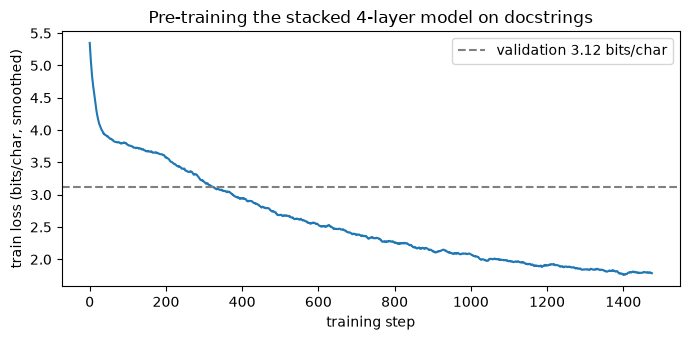

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(len(smooth(stacked_losses))), np.array(smooth(stacked_losses)) / math.log(2))
ax.axhline(STACKED_BPC, color="gray", ls="--", label=f"validation {STACKED_BPC:.2f} bits/char")
ax.set_xlabel("training step")
ax.set_ylabel("train loss (bits/char, smoothed)")
ax.set_title("Pre-training the stacked 4-layer model on docstrings")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Look inside

### 7.1 Toy corpus: tied vs relaxed, one block looped 4 times

Before the real experiments, an interpretable one. We train a **single block looped 4x** strictly tied ($r=0$) and relaxed ($r=4$, four LoRAs),
on the 4 toy sentences. A perfect model has 1 bit of uncertainty at exactly two characters (*m/r* of model/robot and
*w/s* of write/spell) and 0 bits elsewhere: total 2 bits per sentence.

In [14]:
toy_ids = torch.stack([tok.encode(BOS + s) for s in TOY_CORPUS])   # (4, 49)
TOY_X, TOY_Y = toy_ids[:, :-1], toy_ids[:, 1:]                        # (4, 48) each


def train_toy(model: nn.Module, steps: int = 300, lr: float = 3e-3) -> list:
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    losses = []
    for _ in range(steps):
        logits = model(TOY_X)
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), TOY_Y.reshape(-1))
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses


toy_results = {}
for name, rank in [("tied 1x4 (r=0)", 0), ("relaxed 1x4 (r=4)", 4)]:
    set_seed(3)
    m = LoopedLM(tok.vocab_size, 64, 4, n_blocks=1, n_loops=4, rank=rank, max_len=CTX)
    t0 = time.time()
    curve = train_toy(m)
    with torch.no_grad():
        logp = F.log_softmax(m(TOY_X), -1)
        bits = -logp.gather(-1, TOY_Y.unsqueeze(-1)).squeeze(-1) / math.log(2)    # (4, 48)
    toy_results[name] = {"model": m, "curve": curve, "bits": bits, "params": count_params(m)["total"]}
    print(f"{name:20s} params {count_params(m)['total']:7,d}  final loss {curve[-1]:.4f}  "
          f"bits/sentence {bits.sum(1).mean():.3f} (ideal 2.000)  {time.time() - t0:.0f}s")

tied 1x4 (r=0)       params  66,979  final loss 0.0305  bits/sentence 2.115 (ideal 2.000)  7s


relaxed 1x4 (r=4)    params  85,411  final loss 0.0307  bits/sentence 2.122 (ideal 2.000)  9s


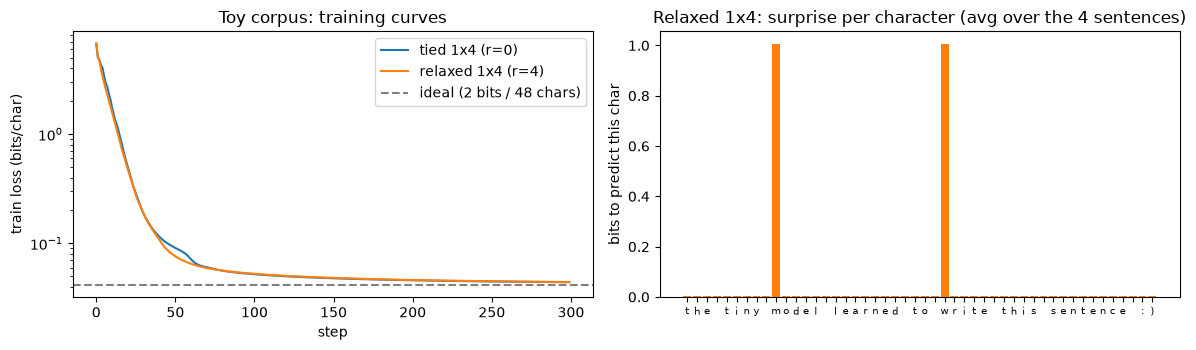

two most uncertain positions: [9, 26] chars: ['m/r', 'w/s'] bits: [1.006 1.006]


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for name, res in toy_results.items():
    axes[0].plot(np.array(res["curve"]) / math.log(2), label=name)
axes[0].axhline(2 / 48, color="gray", ls="--", label="ideal (2 bits / 48 chars)")
axes[0].set_yscale("log")
axes[0].set_xlabel("step")
axes[0].set_ylabel("train loss (bits/char)")
axes[0].set_title("Toy corpus: training curves")
axes[0].legend()

res = toy_results["relaxed 1x4 (r=4)"]
mean_bits = res["bits"].mean(0).numpy()
axes[1].bar(np.arange(48), mean_bits, color="tab:orange")
axes[1].set_xticks(np.arange(48))
axes[1].set_xticklabels(list(TOY_CORPUS[0]), fontsize=7)
axes[1].set_ylabel("bits to predict this char")
axes[1].set_title("Relaxed 1x4: surprise per character (avg over the 4 sentences)")
plt.tight_layout()
plt.show()
top2 = np.argsort(mean_bits)[-2:]
print("two most uncertain positions:", sorted(top2.tolist()), "chars:",
      [TOY_CORPUS[0][i] + "/" + TOY_CORPUS[1 if i < 15 else 2][i] for i in sorted(top2.tolist())],
      "bits:", np.round(mean_bits[sorted(top2.tolist())], 3))

**What we measured.** Both models reach about **2.12 bits per sentence** (ideal 2.00) in 300 full-batch steps, and the bar chart shows almost all of the uncertainty at the two real choice points: position 9 (*m/r*) and position 26 (*w/s*), about 1.006 bits each. The relaxed model (85k parameters) does **no better** than the tied one (67k): this task is too easy to need per-pass specialisation, so the extra LoRA capacity goes unused. Relaxation only pays off when the passes actually have to do different jobs, which is what the docstring experiments below test.

## 8. Experiments

### 8.1 Converting the stacked model into a 2-block-looped-2x model

Three ways to initialise the two shared blocks (section 2): **average**, **stepwise**, **random**. Embeddings, final LayerNorm and head are always
copied from the stacked model. We measure validation bits/char **right after conversion** (no training) and **after
uptraining** for `UPTRAIN_STEPS` steps. For fairness the stacked model is also trained for the same extra steps.

In [16]:
SHARED_PARAM_NAMES = [n for n, _ in RelaxedBlock(8, 2, 1, 0).named_parameters()]   # weights, biases, LayerNorms


def convert(stacked_model: LoopedLM, init: str, rank: int = 0, lora_init: str = "zero", seed: int = 0) -> LoopedLM:
    # Build a K=2, T=2 looped model from a K=4, T=1 stacked model.
    set_seed(seed)
    K, T = 2, 2
    looped = LoopedLM(tok.vocab_size, D_MODEL, N_HEADS, n_blocks=K, n_loops=T, rank=rank, max_len=CTX)
    src = dict(stacked_model.named_parameters())
    dst = dict(looped.named_parameters())
    with torch.no_grad():
        for n in ["tok_emb.weight", "pos_emb.weight", "ln_f.weight", "ln_f.bias", "head.weight", "head.bias"]:
            dst[n].copy_(src[n])
        for k in range(K):
            for pname in SHARED_PARAM_NAMES:
                layers = [src[f"blocks.{t * K + k}.{pname}"] for t in range(T)]   # the layers block k replaces
                if init == "average":
                    dst[f"blocks.{k}.{pname}"].copy_(torch.stack(layers).mean(0))
                elif init == "stepwise":
                    dst[f"blocks.{k}.{pname}"].copy_(src[f"blocks.{2 * k}.{pname}"])   # keep layers 0 and 2
                elif init != "random":
                    raise ValueError(init)
        if rank > 0 and lora_init == "svd":
            for k in range(K):
                for lname, lin in looped.blocks[k].relaxed_linears().items():
                    for t in range(T):
                        W_orig = src[f"blocks.{t * K + k}.{lname}.weight"]
                        residual = W_orig - lin.weight                  # what pass t is missing
                        U, S, Vh = torch.linalg.svd(residual, full_matrices=False)
                        r = min(rank, S.numel())
                        root = S[:r].sqrt()
                        lin.lora_B[t].zero_()
                        lin.lora_A[t].zero_()
                        lin.lora_B[t, :, :r].copy_(U[:, :r] * root)         # (d_out, r)
                        lin.lora_A[t, :r, :].copy_(root[:, None] * Vh[:r])  # (r, d_in)
    return looped


# sanity checks of the conversion code
avg_model = convert(stacked, "average")
w0, w2 = stacked.blocks[0].fc1.weight, stacked.blocks[2].fc1.weight
assert torch.allclose(avg_model.blocks[0].fc1.weight, (w0 + w2) / 2)
step_model = convert(stacked, "stepwise")
assert torch.equal(step_model.blocks[1].attn.q.weight, stacked.blocks[2].attn.q.weight)
# full-rank SVD (r = 64 = min(d_in, d_out) for every matrix here) recovers every stacked weight matrix exactly
full = convert(stacked, "average", rank=64, lora_init="svd")
for k in range(2):
    for t in range(2):
        for lname, lin in full.blocks[k].relaxed_linears().items():
            target = stacked.get_submodule(f"blocks.{t * 2 + k}.{lname}").weight
            assert torch.allclose(lin.merged_weight(t), target, atol=1e-5), (k, t, lname)
print("conversion asserts passed (average, stepwise, full-rank SVD exact recovery)")

conversion asserts passed (average, stepwise, full-rank SVD exact recovery)


In [17]:
results = {}   # name -> dict(params, bpc_convert, bpc_uptrain, curve)


def run_uptrain(name: str, model: nn.Module) -> None:
    bpc0 = val_bpc(model)
    t0 = time.time()
    curve = train(model, UPTRAIN_STEPS, UPTRAIN_LR, seed=1, log_every=0)
    bpc1 = val_bpc(model)
    p = count_params(model)
    results[name] = {"params": p["total"], "lora": p["lora"], "bpc_convert": bpc0, "bpc_uptrain": bpc1,
                     "train_bpc": train_bpc(model),
                     "curve": curve, "model": model, "seconds": time.time() - t0}
    print(f"{name:34s} params {p['total']:7,d}  bpc at conversion {bpc0:6.3f}  after uptrain {bpc1:.3f} (train {results[name]['train_bpc']:.3f})  "
          f"({time.time() - t0:.0f}s)")


# reference: the stacked model itself, trained for the same extra steps
stacked_ref = LoopedLM(tok.vocab_size, D_MODEL, N_HEADS, n_blocks=4, n_loops=1, rank=0, max_len=CTX)
stacked_ref.load_state_dict(stacked.state_dict())
run_uptrain("stacked 4 layers (reference)", stacked_ref)
for init in ["average", "stepwise", "random"]:
    run_uptrain(f"tied 2x2, {init} init", convert(stacked, init))

stacked 4 layers (reference)       params 216,931  bpc at conversion  3.118  after uptrain 3.158 (train 1.670)  (55s)


tied 2x2, average init             params 116,963  bpc at conversion  6.331  after uptrain 3.105 (train 2.243)  (31s)


tied 2x2, stepwise init            params 116,963  bpc at conversion  4.463  after uptrain 3.100 (train 2.031)  (20s)


tied 2x2, random init              params 116,963  bpc at conversion  6.131  after uptrain 3.606 (train 3.083)  (19s)


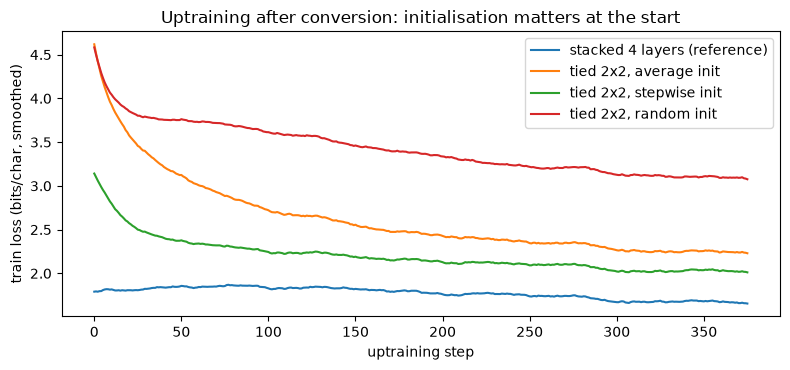

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for name, res in results.items():
    ax.plot(np.arange(len(smooth(res["curve"]))), np.array(smooth(res["curve"])) / math.log(2), label=name)
ax.set_xlabel("uptraining step")
ax.set_ylabel("train loss (bits/char, smoothed)")
ax.set_title("Uptraining after conversion: initialisation matters at the start")
ax.legend()
plt.tight_layout()
plt.show()

**Reading the numbers (single seed).**
- **Right after conversion, averaging is the worst choice:** 6.33 bits/char. That is worse than the 6.13 of random blocks and close to the 6.63 of a uniform guess. The mean of two trained layers is a matrix neither layer was trained to work with. **Stepwise keeps half the network intact** and starts much better (4.46). This agrees with the paper, where stepwise is the best initialisation when there is no LoRA.
- **After 400 uptraining steps the gap between average and stepwise closes** (3.105 vs 3.100). **Pretrained initialisation is worth about 0.5 bits** over random blocks (3.606).
- **Honest caveat about overfitting:** the corpus has only 143k characters. The stacked model is already over-fitted: 400 more steps push its *train* bits/char down to 1.67 but its *validation* score **up** from 3.118 to 3.158. The tied models have half the parameters and overfit less (train 2.03-2.24). So "tied 2x2 beats stacked on validation" here is **regularisation in a data-limited regime, not extra capacity**: on the training windows the stacked model is clearly better (1.67 vs 2.03). A probe outside this notebook gave a validation plateau of 3.14-3.20 for the stacked model across learning rates 1e-3/3e-3 and weight decay 0/0.1, so about 3.1 bits/char is the floor for this data size, not a tuning mistake.

### 8.2 Per-pass LoRA: SVD init vs zero init

Starting from the **average** conversion, we add a rank-8 LoRA to every linear map of every (block, pass) and initialise it either with
zeros ($B_t = 0$, the model starts as the tied model) or with the truncated SVD of $W_{\text{layer}} - W_{\text{shared}}$.

In [19]:
RANK_MAIN = 8
run_uptrain(f"relaxed r={RANK_MAIN}, zero LoRA init", convert(stacked, "average", rank=RANK_MAIN, lora_init="zero"))
run_uptrain(f"relaxed r={RANK_MAIN}, SVD LoRA init", convert(stacked, "average", rank=RANK_MAIN, lora_init="svd"))

relaxed r=8, zero LoRA init        params 153,827  bpc at conversion  6.331  after uptrain 3.084 (train 2.196)  (26s)


relaxed r=8, SVD LoRA init         params 153,827  bpc at conversion  5.740  after uptrain 3.086 (train 1.981)  (17s)


How much of each residual $W_{\text{layer}} - W_{\text{shared}}$ can rank $r$ capture? The singular-value spectrum tells us
before any training: the fraction of squared Frobenius norm kept by the top $r$ singular values.

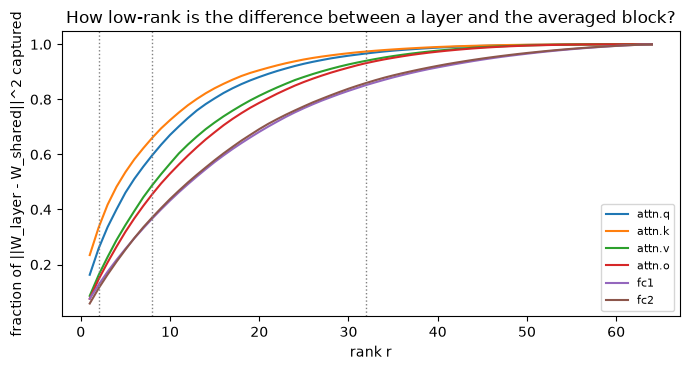

r= 2: energy captured attn.q=0.26, attn.k=0.33, attn.v=0.16, attn.o=0.15, fc1=0.13, fc2=0.11
r= 8: energy captured attn.q=0.60, attn.k=0.66, attn.v=0.49, attn.o=0.46, fc1=0.37, fc2=0.37
r=32: energy captured attn.q=0.97, attn.k=0.97, attn.v=0.94, attn.o=0.93, fc1=0.85, fc2=0.86


In [20]:
avg_model = convert(stacked, "average")
energy = {}
for lname in RelaxedBlock.LINEAR_NAMES:
    curves = []
    for k in range(2):
        for t in range(2):
            W_orig = stacked.get_submodule(f"blocks.{t * 2 + k}.{lname}").weight
            W_shared = avg_model.blocks[k].get_submodule(lname).weight
            S = torch.linalg.svdvals((W_orig - W_shared).detach())
            curves.append(torch.cumsum(S ** 2, 0) / (S ** 2).sum())
    energy[lname] = torch.stack(curves).mean(0).numpy()

fig, ax = plt.subplots(figsize=(7, 3.8))
for lname, e in energy.items():
    ax.plot(np.arange(1, len(e) + 1), e, label=lname)
for r in [2, 8, 32]:
    ax.axvline(r, color="gray", ls=":", lw=1)
ax.set_xlabel("rank r")
ax.set_ylabel("fraction of ||W_layer - W_shared||^2 captured")
ax.set_title("How low-rank is the difference between a layer and the averaged block?")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
for r in [2, 8, 32]:
    print(f"r={r:2d}: energy captured " + ", ".join(f"{n}={energy[n][r - 1]:.2f}" for n in energy))

**What SVD init recovers.** With $r=8$, the SVD init lowers the conversion score from 6.33 to 5.74 bits/char. Zero init starts *exactly* at the tied model's 6.33, as the asserts promised. After uptraining the two inits have the **same validation score** (3.086 vs 3.084). The SVD-initialised model fits the training text better (train 1.98 vs 2.20), so it keeps more of the teacher, but in this data-limited setting that does not carry over to validation.

**Why rank 8 recovers so little at conversion:** the residuals $W_{\text{layer}} - W_{\text{shared}}$ are **not low rank**. Rank 8 captures only 37-66% of their energy (the MLP matrices are the least compressible), and it takes $r=32$ to capture 85-97%. Small trained models apparently use their weight matrices fairly evenly, so a few directions cannot summarise the difference between two layers.

### 8.3 Rank sweep: parameters vs validation bits/char

SVD-initialised LoRA on the average conversion, $r \in \{0, 2, 8, 32\}$ ($r=0$ is the strictly tied model from 8.1, $r=8$ is from 8.2).
We first measure every rank (including $r = 16, 64$) **right after conversion** (no training, cheap), then uptrain $r = 2$ and $r = 32$.

In [21]:
conv_only = {}
for r in [0, 2, 8, 16, 32, 64]:
    m = convert(stacked, "average", rank=r, lora_init="svd")
    conv_only[r] = (count_params(m)["total"], val_bpc(m))
    print(f"r={r:2d}: params {conv_only[r][0]:7,d}  bpc right after conversion {conv_only[r][1]:.3f}")
print(f"stacked teacher: params {count_params(stacked)['total']:,d}  bpc {STACKED_BPC:.3f}")

for r in [2, 32]:
    run_uptrain(f"relaxed r={r}, SVD LoRA init", convert(stacked, "average", rank=r, lora_init="svd"))

r= 0: params 116,963  bpc right after conversion 6.331


r= 2: params 126,179  bpc right after conversion 6.240


r= 8: params 153,827  bpc right after conversion 5.740


r=16: params 190,691  bpc right after conversion 4.656


r=32: params 264,419  bpc right after conversion 3.487


r=64: params 411,875  bpc right after conversion 3.236
stacked teacher: params 216,931  bpc 3.118


relaxed r=2, SVD LoRA init         params 126,179  bpc at conversion  6.240  after uptrain 3.088 (train 2.158)  (15s)


relaxed r=32, SVD LoRA init        params 264,419  bpc at conversion  3.487  after uptrain 3.134 (train 1.724)  (16s)


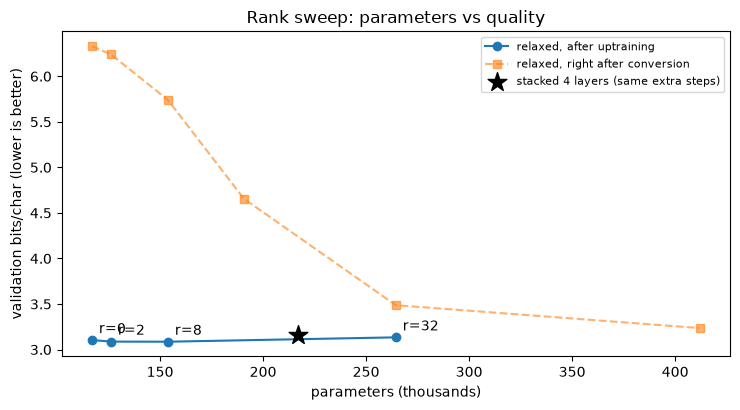

In [22]:
sweep = {0: results["tied 2x2, average init"], 2: results["relaxed r=2, SVD LoRA init"],
         8: results[f"relaxed r={RANK_MAIN}, SVD LoRA init"], 32: results["relaxed r=32, SVD LoRA init"]}
ref = results["stacked 4 layers (reference)"]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
xs = [sweep[r]["params"] / 1e3 for r in sweep]
ax.plot(xs, [sweep[r]["bpc_uptrain"] for r in sweep], "o-", label="relaxed, after uptraining")
ax.plot([conv_only[r][0] / 1e3 for r in conv_only], [conv_only[r][1] for r in conv_only], "s--", alpha=0.6,
        label="relaxed, right after conversion")
for r in sweep:
    ax.annotate(f"r={r}", (sweep[r]["params"] / 1e3, sweep[r]["bpc_uptrain"]), textcoords="offset points", xytext=(5, 5))
ax.scatter([ref["params"] / 1e3], [ref["bpc_uptrain"]], marker="*", s=200, color="black", zorder=5,
           label="stacked 4 layers (same extra steps)")
ax.set_xlabel("parameters (thousands)")
ax.set_ylabel("validation bits/char (lower is better)")
ax.set_title("Rank sweep: parameters vs quality")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 8.4 Results table and parameter / compute accounting

"MACs/token" counts multiply-adds of the linear layers in the blocks (attention score cost is identical for all models
and left out). All 2x2 models apply a block 4 times per token, exactly like the stacked model, so **looping saves parameters, not compute**;
the LoRA adds a little compute on top.

In [23]:
def block_macs_per_token(d: int, rank: int, applications: int) -> int:
    dense = 4 * d * d + 2 * d * 4 * d                       # q,k,v,o + fc1 + fc2
    lora = rank * (4 * 2 * d + 2 * 5 * d) if rank > 0 else 0   # B_t(A_t x) for every linear
    return applications * (dense + lora)


rank_of = {"stacked 4 layers (reference)": 0, "tied 2x2, average init": 0, "tied 2x2, stepwise init": 0,
           "tied 2x2, random init": 0}
print(f"{'model':36s} {'params':>8s} {'LoRA':>7s} {'MACs/tok':>9s} {'bpc@convert':>12s} {'bpc@uptrain':>12s} {'train bpc':>10s} {'sec':>5s}")
for name, res in results.items():
    r = rank_of.get(name, int(re.search(r"r=(\d+)", name).group(1)) if "r=" in name else 0)
    macs = block_macs_per_token(D_MODEL, r, 4)
    print(f"{name:36s} {res['params']:8,d} {res['lora']:7,d} {macs:9,d} {res['bpc_convert']:12.3f} "
          f"{res['bpc_uptrain']:12.3f} {res['train_bpc']:10.3f} {res['seconds']:5.0f}")

# parameter accounting check: LoRA params = n_blocks * sum over linears of T * r * (d_in + d_out)
for r in [2, 8, 32]:
    expected = 2 * 2 * r * 18 * D_MODEL
    assert sweep[r]["lora"] == expected, (r, sweep[r]["lora"], expected)
print("\nLoRA parameter count matches 2 blocks x T=2 x r x 18d for r = 2, 8, 32")

model                                  params    LoRA  MACs/tok  bpc@convert  bpc@uptrain  train bpc   sec
stacked 4 layers (reference)          216,931       0   196,608        3.118        3.158      1.670    55
tied 2x2, average init                116,963       0   196,608        6.331        3.105      2.243    31
tied 2x2, stepwise init               116,963       0   196,608        4.463        3.100      2.031    20
tied 2x2, random init                 116,963       0   196,608        6.131        3.606      3.083    19
relaxed r=8, zero LoRA init           153,827  36,864   233,472        6.331        3.084      2.196    26
relaxed r=8, SVD LoRA init            153,827  36,864   233,472        5.740        3.086      1.981    17
relaxed r=2, SVD LoRA init            126,179   9,216   205,824        6.240        3.088      2.158    15
relaxed r=32, SVD LoRA init           264,419 147,456   344,064        3.487        3.134      1.724    16

LoRA parameter count matches 2 block

**Rank sweep, in numbers.**
- **Right after conversion**, bits/char fall steadily with rank: 6.33 (r=0), 6.24 (2), 5.74 (8), 4.66 (16), 3.49 (32), 3.24 (64). At $r=64$ every weight matrix of the teacher is recovered exactly (asserted). The remaining 0.12-bit gap to the teacher's 3.118 is caused **entirely by the shared biases and LayerNorms** (exercise 1).
- **After uptraining**, validation is nearly flat: 3.105 (r=0), 3.088 (2), 3.086 (8), 3.134 (32), against 3.158 for the stacked reference. The 0.02-bit spread between r=0 and r=8 comes from a single seed and is probably within noise. **r=32 is worse on validation but best on train** (1.72, close to the stacked model's 1.67): more capacity, more overfitting.
- **Parameter cost is not small at this width:** $18rd$ per block and pass means $r=32$ (264k parameters) is **bigger than the stacked model** (217k). LoRA is cheap only when $r \ll d$; in the paper $d$ is in the thousands. Compute grows too: +4.7% multiply-adds per token at $r=2$, +19% at $r=8$, +75% at $r=32$.
- **Bottom line for this tiny setting:** a strictly tied 2x2 model with a pretrained initialisation already matches the stacked model on held-out text with 54% of the parameters. The per-pass LoRA buys training-set fit roughly in proportion to its rank, but very little held-out quality. The paper's large gains come from the opposite regime, with huge pretrained models and plenty of data, where the tied model is under-fitting.

### 8.5 Inside the trained relaxed model: $W$, $\Delta_t$ and per-pass delta norms

For the rank-8 SVD-initialised model after uptraining: the shared query weight of block A, the two per-pass corrections
$\Delta_0, \Delta_1$, and the "ideal" corrections we started from ($W_{\text{layer}} - W_{\text{shared}}$ of the teacher).

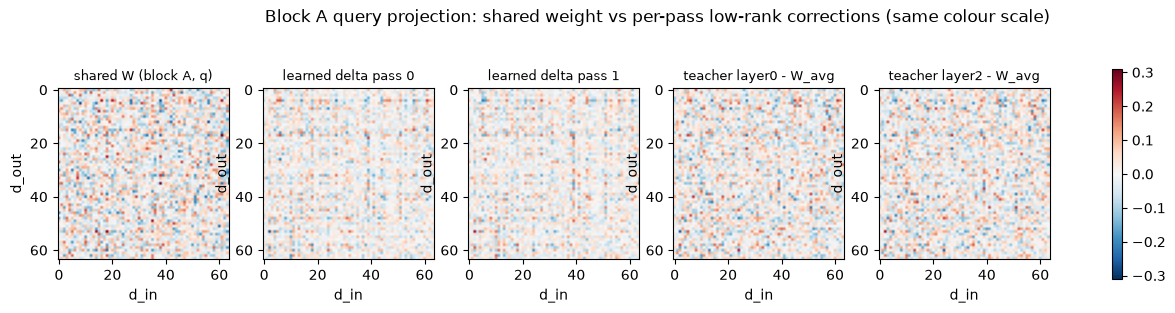

pass 0: ||delta|| / ||W|| = 0.721   cosine(learned delta, teacher residual) = 0.760
pass 1: ||delta|| / ||W|| = 0.711   cosine(learned delta, teacher residual) = 0.754


In [24]:
relaxed8 = results[f"relaxed r={RANK_MAIN}, SVD LoRA init"]["model"]
q = relaxed8.blocks[0].attn.q
with torch.no_grad():
    W = q.weight.detach()
    deltas = [q.delta(t).detach() for t in range(2)]
    ideal = [(stacked.blocks[t * 2].attn.q.weight - convert(stacked, "average").blocks[0].attn.q.weight).detach()
             for t in range(2)]

mats = [W, deltas[0], deltas[1], ideal[0], ideal[1]]
titles = ["shared W (block A, q)", "learned delta pass 0", "learned delta pass 1",
          "teacher layer0 - W_avg", "teacher layer2 - W_avg"]
vmax = float(max(m.abs().max() for m in mats))
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, m, title in zip(axes, mats, titles):
    im = ax.imshow(m.numpy(), cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("d_in")
    ax.set_ylabel("d_out")
fig.colorbar(im, ax=axes, shrink=0.8)
fig.suptitle("Block A query projection: shared weight vs per-pass low-rank corrections (same colour scale)")
plt.show()
for t in range(2):
    cos = F.cosine_similarity(deltas[t].flatten(), ideal[t].flatten(), dim=0).item()
    print(f"pass {t}: ||delta|| / ||W|| = {deltas[t].norm() / W.norm():.3f}   "
          f"cosine(learned delta, teacher residual) = {cos:.3f}")

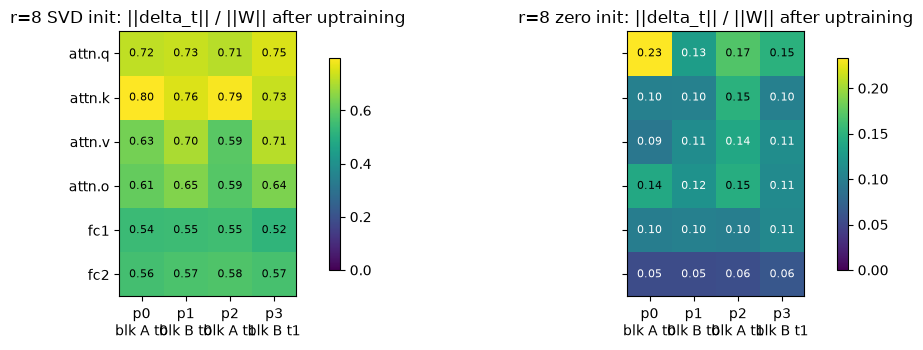

r=8 SVD init: mean relative delta norm 0.648, max 0.798
r=8 zero init: mean relative delta norm 0.115, max 0.233


In [25]:
models_to_show = {"r=8 SVD init": results[f"relaxed r={RANK_MAIN}, SVD LoRA init"]["model"],
                  "r=8 zero init": results[f"relaxed r={RANK_MAIN}, zero LoRA init"]["model"]}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
norm_table = {}
for ax, (label, model) in zip(axes, models_to_show.items()):
    grid = np.zeros((len(RelaxedBlock.LINEAR_NAMES), 4))
    for k in range(2):
        for j, (lname, lin) in enumerate(model.blocks[k].relaxed_linears().items()):
            for t in range(2):
                grid[j, t * 2 + k] = (lin.delta(t).norm() / lin.weight.norm()).item()
    norm_table[label] = grid
    im = ax.imshow(grid, cmap="viridis", vmin=0)
    ax.set_xticks(range(4))
    ax.set_xticklabels([f"p{p}\nblk {'AB'[p % 2]} t{p // 2}" for p in range(4)])
    ax.set_yticks(range(len(RelaxedBlock.LINEAR_NAMES)))
    ax.set_yticklabels(RelaxedBlock.LINEAR_NAMES)
    for (i, j), v in np.ndenumerate(grid):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v < grid.max() * 0.6 else "black", fontsize=8)
    ax.set_title(f"{label}: ||delta_t|| / ||W|| after uptraining")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()
for label, grid in norm_table.items():
    print(f"{label}: mean relative delta norm {grid.mean():.3f}, max {grid.max():.3f}")

**What the deltas look like.** In the SVD-initialised model the query corrections stay large after uptraining: $\|\Delta_t\|/\|W\| \approx 0.72$, with a cosine of about 0.76 to the teacher residual they were initialised from. Uptraining nudges the SVD init but does not discard it. The two inits end in **very different places for the same validation score**: zero-init deltas grow to a mean relative norm of only 0.115 (max 0.23) in 400 steps, against 0.648 for SVD init. A zero-initialised relaxed model stays a small perturbation of the tied model, while an SVD-initialised one stays close to the stacked teacher. The heatmaps show the low-rank structure directly: each learned delta is made of a few strong row and column patterns, unlike the dense shared $W$.

## 9. Common pitfalls & debugging tips

- **Always measure right after conversion.** Averaging trained layers gave 6.33 bits/char, *worse than random blocks* (6.13). Without that number you would blame uptraining for a bad initialisation.
- **LoRA with $B=0$: only $B$ gets gradient at step 0** (we measured $\max|\partial L/\partial A| = 0$ exactly). If you also initialise $A = 0$, *both* gradients are zero forever and the LoRA never trains.
- **Watch train and validation together.** On 143k characters the stacked model's validation score rises (3.118 to 3.158) while its train score keeps falling. A model that "wins" on validation may just be smaller.
- **Full-rank SVD does not reproduce the teacher** (3.236 vs 3.118) because biases and LayerNorms are still shared. If an exact-recovery test fails, check those before you suspect the SVD.
- **Count LoRA parameters at your width.** $T r (d_{in}+d_{out})$ is cheap only when $r \ll d$; at $d=64$, $r=32$ makes the relaxed model larger than the stacked one.
- **Stepwise + SVD:** the kept layers have a residual of exactly zero (their LoRA is all zeros), so only the dropped layers get a correction. Averaging spreads the residual over every pass.
- **`nn.MultiheadAttention` hides its projections.** Write $q,k,v,o$ as your own linears so each pass can add its delta, and pass `is_causal=True` to `F.scaled_dot_product_attention` (we asserted that it equals a manual masked softmax and that no future information leaks).
- **One seed.** Differences under about 0.03 bits/char here are not resolved; rerun with several seeds before drawing conclusions from them.

## 10. Recap

- **Strict tying** re-applies one function per block. **Relaxed recursion** adds a per-pass low-rank delta $W_t = W + B_tA_t$, which costs $T r(d_{in}+d_{out})$ parameters per linear.
- **$B_t = 0$ makes the relaxed model start exactly at the tied model** (asserted bit-for-bit), and changing $B_t$ only affects pass $t$ and what comes after it (asserted).
- **Converting a stacked model:** stepwise starts best (4.46 vs 6.33 for average and 6.13 for random). After 400 steps average and stepwise tie (3.10), and both beat random blocks by about 0.5 bits.
- **SVD-initialised LoRA** recovers the teacher in proportion to rank (exactly at full rank, up to the shared biases and norms). After uptraining it improves training fit but, on this small corpus, not validation: r=0/2/8 all land at about 3.09-3.11 and r=32 at 3.13, against 3.16 for the stacked model trained for as long.

### Cheat sheet

| Thing | Formula / code |
|---|---|
| Relaxed linear | `y = F.linear(x, W, b) + (x @ A[t].T) @ B[t].T` |
| Extra params per linear | $T \cdot r \cdot (d_{in} + d_{out})$; per block and pass $18 r d$ for our block |
| Zero init | `A ~ N(0, 1/d_in)`, `B = 0`, model == tied model; $\partial L/\partial A = 0$ at step 0 |
| Average conversion | `W_k = mean(W[t*K + k] for t in range(T))` |
| Stepwise conversion | keep layers at regular intervals (here 0 and 2) |
| SVD LoRA init | `U,S,Vh = svd(W_layer - W_shared)`, `B = U[:, :r] * S[:r]**.5`, `A = S[:r, None]**.5 * Vh[:r]` |
| Exact recovery | $r = \min(d_{in}, d_{out})$ recovers every weight matrix (biases/LayerNorms still shared) |
| Compute | looping saves *parameters*, not FLOPs; LoRA adds $r(d_{in}+d_{out})$ MACs per linear per token |

### Exercises

1. **Relax the LayerNorms and biases too.** Give every pass its own LayerNorm gains and biases (a few hundred parameters).
   *Hint:* store them as `(T, d)` tensors and index with `t` like `lora_A`. Does the $r=64$ "conversion only" model now
   match the stacked teacher's bits/char exactly? It should; turn that into an `assert`.
2. **One block looped 4x.** Convert the stacked model into `n_blocks=1, n_loops=4` (average of all 4 layers) and repeat the
   rank sweep. *Hint:* in `convert`, `K=1, T=4`; the residuals $W_\ell - \bar W$ are larger, so you should need a higher rank for the same quality.
3. **Truncate gradually.** Instead of keeping the SVD-initialised LoRA, fine-tune with an increasing penalty $\lambda \sum_t \|B_t A_t\|_F^2$
   and watch how the per-pass deltas shrink. *Hint:* compute `lin.delta(t).pow(2).sum()` for all linears and add it to the loss;
   plot validation bits/char against $\lambda$.

### References
- S. Bae, A. Fisch, H. Harutyunyan, Z. Ji, S. Kim, T. Schuster. *Relaxed Recursive Transformers: Effective Parameter Sharing with Layer-wise LoRA.* arXiv:2410.20672 (2024).
- E. J. Hu et al. *LoRA: Low-Rank Adaptation of Large Language Models.* arXiv:2106.09685 (2021).
- M. Dehghani, S. Gouws, O. Vinyals, J. Uszkoreit, Ł. Kaiser. *Universal Transformers.* arXiv:1807.03819 (2018).

In [26]:
print(f"total notebook runtime: {time.time() - NOTEBOOK_START:.0f} s")

total notebook runtime: 384 s
